# Assignment #3 - Academic Environment Representation

### Problem statement
Consider a university that needs a knowledge representation system to describe its academic environment. The system must represent students, professors, courses, departments, and research projects.

The following information is known:

- Every person has a name, an identification number, and an email address.
- A student is a person who has a student number and enrolls in courses.
- A professor is a person who has an academic rank and teaches courses.
- Every course has a course code, title, and credit hours.
- Each course belongs to a department.
- A professor may supervise several research projects.
- A research project has a title, a principal investigator, and one or more participating researchers.
- A postgraduate student may participate in a research project under a professor's supervision.

Your task is to develop an object-oriented representation of this domain and explain how the representation captures the relevant knowledge.

________________

### Utility Function for Drawing UML Class Diagrams


In [89]:
import base64
import urllib.request
from IPython.display import Image, display

### Utility Function for Drawing UML Class Diagrams
def draw_class_diagram(mermaid_objects):
    encoded = base64.urlsafe_b64encode(mermaid_objects.encode("utf-8")).decode("utf-8")
    url = f"https://mermaid.ink/img/{encoded}"
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as response:
        img_bytes = response.read()

    display(Image(data=img_bytes))

## **Task 1: Identify classes and instances**
Identify at least six classes required to represent the domain. For each class, provide two possible instances.

<pre>
    1- Person
        - person_lina(id -> 99999102, name -> Lina, email -> lina@university.edu)
        - Person_samir(id -> 99999301, name -> Samir, email -> samir@university.edu)

    2- Student is_a Person
        - student_lina(student_number -> 102)
        - student_salem(student_number -> 202)

    3- Postgraduate_Student is_a Student
        - postgraduate_student_lina()
        - postgraduate_student_salem()

    4- Professor is_a Person
        - professor_Samir(academic_rank -> "professor")
        - professor_khalid(academic_rank -> "Associate professor")

    5- Course
        - course_knowledge_representation(code -> 491112, credit_hours -> 3, title -> "Knowledge Representation")
        - course_big_data_analytics(code -> 489124, credit_hours -> 3, title -> "Big Data Analytics")

    6- Department
        - department_5211(code -> 5211, name -> "Artificial Intelligence"): 
        - department_8320(code -> 8320, name -> "Cybersecurity") 

    7- Research_Project
        - research_01(title -> "Medical Ontology Development")
        - research_02(title -> "Measuring Similarity Between Research Papers with Spark RDDs")
</pre>

____________________

## **Task 2: Define attributes and relationships**

For each class, specify its attributes and identify its relationships with other classes.<br>
Distinguish between attributes that describe an object and relationships that connect it to other objects.<br>
#### Attributes whose names end with __rel represent relationships between objects, while all other attributes describe object properties.

#### - <b>Entity Frames</b>

<pre>
(Person
    <:id Integer>
    <:name String>
    <:email String>)
</pre>

<pre>
(Student
    <<b>:IS-A</b> Person>
    <:student_number Integer>)
</pre>

<pre>
(Postgraduate_Student
    <<b>:IS-A</b> Student>)
</pre>

<pre>
(Professor
    <<b>:IS-A</b> Person>
    <:academic_rank String>)
</pre>

<pre>
(Course
    <:code String>
    <:title String>
    <:credit_hours Integer>
    <:department<b>__rel</b> Department>
    <:teacher<b>__rel</b> Professor>)
</pre>

<pre>
(Department
    <:id Integer>
    <:name String>)
</pre>

<pre>
(Research_Project
    <:title String>
    <:investigator<b>__rel</b> Professor>)
</pre>


#### - <b>Relationship Frames</b>
<pre>
(Course_Enrollment
    <:course<b>__rel</b> Course>
    <:student<b>__rel</b> Student>)
</pre>
* This relationship frame needed to represent many-to-many relationship between Course and Student <br/><br/>

<pre>
(Research_Participation
    <:project<b>__rel</b> Research_Project>
    <:participant<b>__rel</b> Postgraduate_Student>)
</pre>
* This relationship frame needed to represent many-to-many relationship between Project and Student


___________________

## **Task 3: Represent inheritance**

Develop an inheritance hierarchy that includes Person, Student, and Professor.

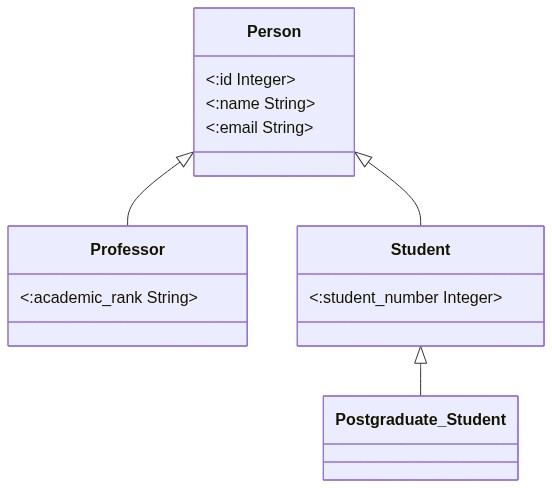

In [90]:
draw_class_diagram("""
classDiagram
    class Person {
        <:id Integer>
        <:name String>
        <:email String>
    }
    class Professor {
        <:academic_rank String>
    }
    class Student {
        <:student_number Integer>
    }
    class Postgraduate_Student {
    }
    
    %% Inheritance (IS-A)
    Person <|-- Student
    Student <|-- Postgraduate_Student
    Person <|-- Professor
""")

### Explanation:

* **Which attributes are inherited by subclasses?**
  * `id`, `name`, and `email` are defined once in `Person` and are automatically inherited by both `Student` and `Professor` subclasses.
  * `Postgraduate_Student` automatically inherit `student_number` from `Student` as well as `id`, `name`, and `email` from `Person`.

* **Why Student and Professor should be modeled as subclasses of Person:**
  * Both students and professors are human entities that share identical core properties (`id`, `name`, `email`). Modeling them as subclasses avoids code duplication, ensures consistent data-types across the application.

* **Whether a person could be both a student and a professor, and how your model would handle that situation:**<br>
    **No**, under the current design, a person cannot be both a student and a professor.

    * `Student` and `Professor` are modeled as parallel, disjoint subclasses of `Person`. In standard object-oriented, an object can only be instantiated as a single leaf class in the hierarchy.

    * **Suggested Solution:** Instead of inheriting `Person` into two different subclasses, we can use Role Aggregation/Composition. We add a relationship attribute named `Roles` of type `Array[Role]` to `Person`, where `Role` is an abstract class with `StudentRole` and `ProfessorRole` as subclasses. 
    Connecting `Person` to `Role` via a 1-to-many composition relationship, allows a single `Person` instance to hold both `StudentRole` and `ProfessorRole` objects simultaneously.

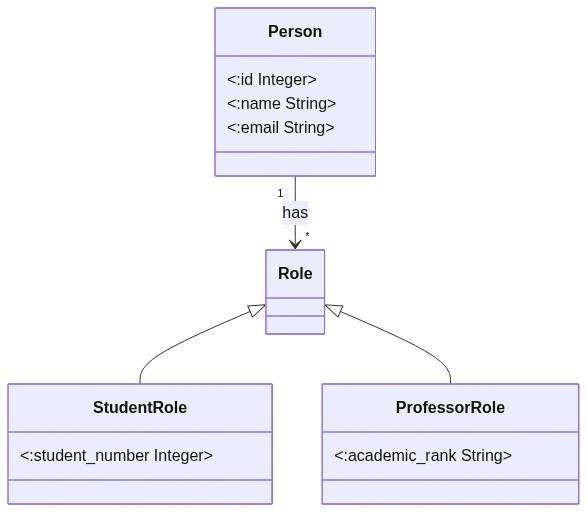

In [91]:
draw_class_diagram("""
classDiagram
    class Person {
        <:id Integer>
        <:name String>
        <:email String>
    }
    class Role {
    }
    class StudentRole {
        <:student_number Integer>
    }
    class ProfessorRole {
        <:academic_rank String>
    }

    Person "1" --> "*" Role : has
    Role <|-- StudentRole
    Role <|-- ProfessorRole""")

______________

## **Task 4: Object representation**

Represent the following individuals as objects using a notation of your choice, such as UML class diagrams, tables, or structured pseudocode.

<pre>
Student: Lina, student number S102, email lina@university.edu.
Professor: Dr. Samir, associate professor, email samir@university.edu.
Course: KR501, Knowledge Representation, 3 credit hours.
Research project: Medical Ontology Development, supervised by Dr. Samir, with Lina as a participating researcher.
</pre>

Show how the objects are connected and ensure that the representation is consistent with your class definitions.

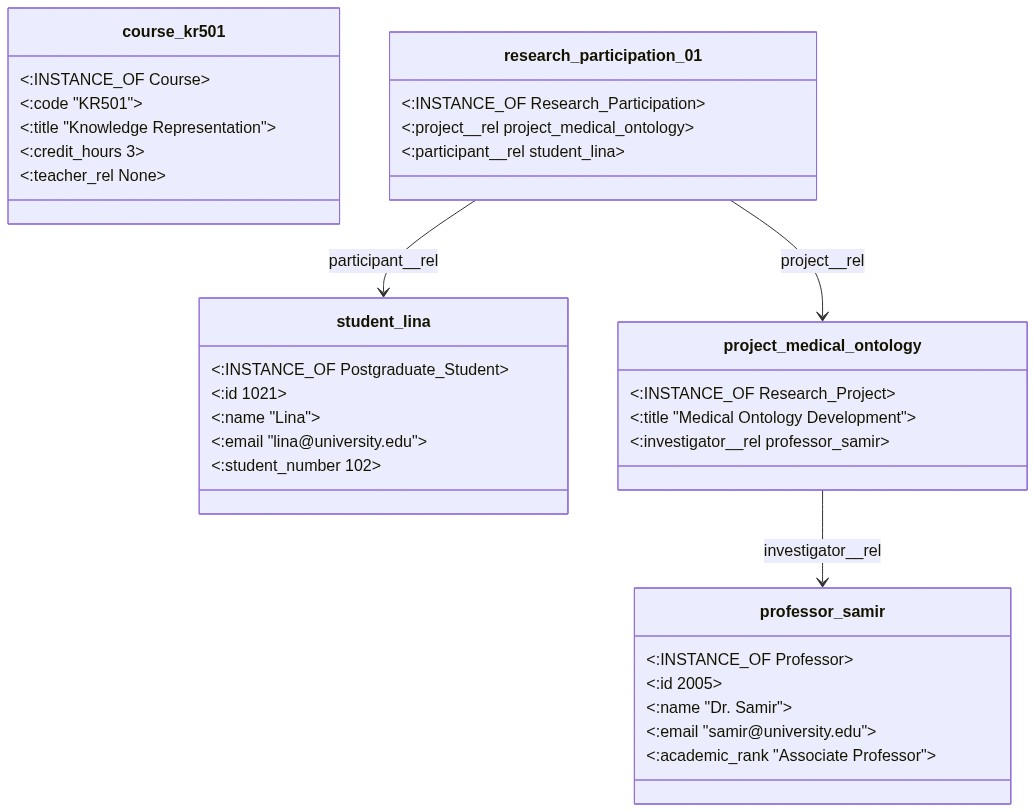

In [92]:
draw_class_diagram("""
classDiagram
    class student_lina {
        <:INSTANCE_OF Postgraduate_Student>
        <:id 1021>
        <:name "Lina">
        <:email "lina@university.edu">
        <:student_number 102>
    }

    class professor_samir {
        <:INSTANCE_OF Professor>
        <:id 2005>
        <:name "Dr. Samir">
        <:email "samir@university.edu">
        <:academic_rank "Associate Professor">
    }

    class course_kr501 {
        <:INSTANCE_OF Course>
        <:code "KR501">
        <:title "Knowledge Representation">
        <:credit_hours 3>
        <:teacher_rel None>
    }

    class project_medical_ontology {
        <:INSTANCE_OF Research_Project>
        <:title "Medical Ontology Development">
        <:investigator__rel professor_samir>
    }

    class research_participation_01 {
        <:INSTANCE_OF Research_Participation>
        <:project__rel project_medical_ontology>
        <:participant__rel student_lina>
    }

    %% Only explicitly mentioned relationships
    project_medical_ontology --> professor_samir : investigator__rel
    research_participation_01 --> project_medical_ontology : project__rel
    research_participation_01 --> student_lina : participant__rel
""")

### There is no explicit information in the object descriptions above showing who teaches the kr501 course or who is enrolled in it. Therefore, we kept it as a disconnected node.

___________________

### **Full class diagram of the system showing generic frames and their relationships.**

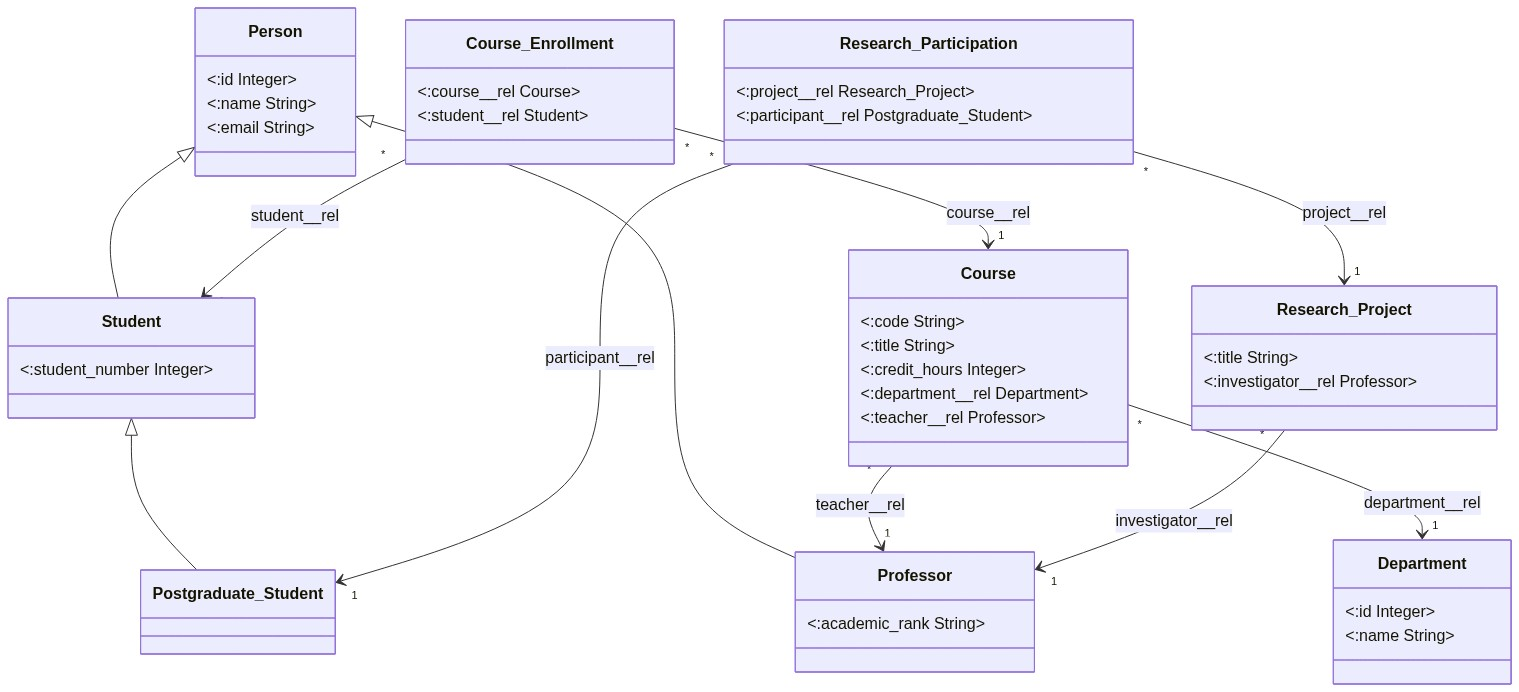

In [93]:
draw_class_diagram("""
classDiagram
    class Person {
        <:id Integer>
        <:name String>
        <:email String>
    }

    class Student {
        <:student_number Integer>
    }

    class Postgraduate_Student {
    }

    class Professor {
        <:academic_rank String>
    }

    class Department {
        <:id Integer>
        <:name String>
    }

    class Course {
        <:code String>
        <:title String>
        <:credit_hours Integer>
        <:department__rel Department>
        <:teacher__rel Professor>
    }

    class Research_Project {
        <:title String>
        <:investigator__rel Professor>
    }

    class Course_Enrollment {
        <:course__rel Course>
        <:student__rel Student>
    }

    class Research_Participation {
        <:project__rel Research_Project>
        <:participant__rel Postgraduate_Student>
    }

    %% Inheritance (IS-A)
    Person <|-- Student
    Student <|-- Postgraduate_Student
    Person <|-- Professor

    %% Entity Object References (Slot Relations)
    Course "*" --> "1" Department : department__rel
    Course "*" --> "1" Professor : teacher__rel
    Research_Project "*" --> "1" Professor : investigator__rel

    %% Reified Relationship Frames
    Course_Enrollment "*" --> "1" Course : course__rel
    Course_Enrollment "*" --> "1" Student : student__rel
    Research_Participation "*" --> "1" Research_Project : project__rel
    Research_Participation "*" --> "1" Postgraduate_Student : participant__rel
""")